# Machine Learning using Sentinel-2 Data

<div><img src="https://github.com/digitalearthpacific/DigitalEarthPacific/blob/main/notebooks/DEP_LCAST/reference_materials/images/1B/1.a.png?raw=true" width="500"/></div>

This example uses training data from the
[Coast Train](https://github.com/nick-murray/coastTrain) dataset
along with Sentinel-2 data to demonstrate how to use a
machine learning classifier, in this case, Random Forest, to
assign a class to each pixel.

This notebook combines lessons from previous notebooks into
a comprehensive worked example.

## Workshop-enhanced version

This version retains the original teaching workflow while adding:
- stronger Sentinel-2 SCL cloud masking;
- minimum clear-observation protection;
- red-edge, SWIR, NDVI, NDMI, NDRE and NDBI indicators;
- temporal/phenology variability indicators;
- class-balanced Random Forest;
- 80/20 accuracy assessment and confusion matrix;
- automatic identification of classes needing more ground observations;
- analysis of the most common class-confusion pairs;
- model confidence/uncertainty;
- a **New AOI of your interest** section where participants can apply the trained model to their own polygon or bounding box using exactly the same indicators.

The New AOI result is a transfer prediction and should be locally validated.


## Getting started

First we load the required Python libraries and tools.

In [1]:
from pystac_client import Client
from dask.distributed import Client as DaskClient
from odc.stac import load, configure_s3_access
import geopandas as gpd
import pandas as pd
import numpy as np
import xarray as xr
import folium
import joblib
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

import odc.geo.xr  # noqa: F401


## Study site configuration

Here we establish the STAC catalog we're using as well as a
spatial and temporal extent. This can be anywhere, but this location
near Kuching was chosen due to the training data having several
classes available.

In [2]:
# STAC Catalog URL
# catalog = "https://stac.staging.digitalearthpacific.org"
catalog = "https://earth-search.aws.element84.com/v1"
# Create a STAC Client
client = Client.open(catalog)

<font color='blue'>1.1. Define your area of interest. Find the coordinates of the bottom left and top right corners of your bounding box / area of interest. 

Use QGIS, Google Maps or another site to find the coordinates. Make sure to use at least 4 or 5 decimal places. Lat = latitude and lon = longitude. The min is in the bottom left and max is in the top right.   

In [3]:
# # 1.1 - input your four coordinates here 
# min_lat = -17.631319
# min_lon = 177.968450
# max_lat = -17.621633
# max_lon = 177.975529

# bbox = (min_lon, min_lat, max_lon, max_lat)

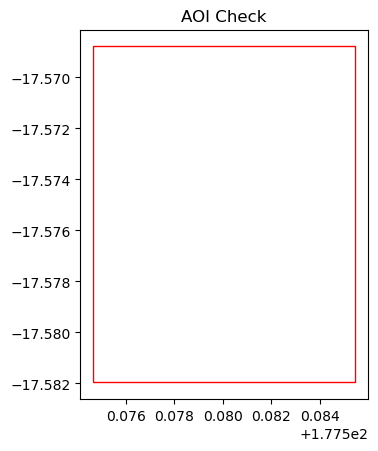

In [36]:
# Define bounding box – should match your area
aoi_gdf = gpd.read_file("AOI/Lololo_2.geojson")
aoi_gdf.plot(edgecolor="red", facecolor="none")
plt.title("AOI Check")
plt.show()  # Replace with actual coordinates

In [37]:
bbox = aoi_gdf.total_bounds  # returns [minx, miny, maxx, maxy]

In [38]:
center = [
    aoi_gdf.geometry.centroid.y.mean(),
    aoi_gdf.geometry.centroid.x.mean()
]

m = folium.Map(location=center, zoom_start=10)

folium.GeoJson(
    aoi_gdf,
    style_function=lambda x: {
        "fillColor": "none",
        "color": "red",
        "weight": 2
    }
).add_to(m)

m

/tmp/ipykernel_379/1827346902.py:2: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  aoi_gdf.geometry.centroid.y.mean(),
/tmp/ipykernel_379/1827346902.py:3: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  aoi_gdf.geometry.centroid.x.mean()


In [39]:
min_lat = aoi_gdf['geometry'].bounds['miny'].min()
max_lat = aoi_gdf['geometry'].bounds['maxy'].max()
min_lon = aoi_gdf['geometry'].bounds['minx'].min()
max_lon = aoi_gdf['geometry'].bounds['maxx'].max()

<font color='blue'>1.2. Define the time period of interest. 

You can now define the time you are interested in. It is goood to put the format as "year-month"/"year-month". For example "2022-06/2024-09" to get all images covering June 2022 to September 2024. You can try to just choose the flowering months in one year but may have issues with cloud cover. Try different time periods and see what happes. 

In [40]:
# 1.2 - input your datetime here - recommend at least 3 months and max 3 years. 
datetime = "2025-06/2025-11"

In [41]:
# Create local dask cluster to improve data load time. Only run this once.
dask_client = DaskClient(n_workers=1, threads_per_worker=16, memory_limit='16GB')

# Configure S3 access. Cloud defaults is an optimisation, while requester pays is required for Landsat
configure_s3_access(cloud_defaults=True, requester_pays=True)

/srv/conda/envs/notebook/lib/python3.11/site-packages/distributed/node.py:187: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 46137 instead
  warnings.warn(
2026-10-11 21:58:18,985 - distributed.scheduler - WARNING - Detected different `run_spec` for key ('sum-799c8fabfc1f9923ebf58bdaec54f84c', 17, 0, 0) between two consecutive calls to `update_graph`. This can cause failures and deadlocks down the line. Please ensure unique key names. If you are using a standard dask collections, consider releasing all the data before resubmitting another computation. More details and help can be found at https://github.com/dask/dask/issues/9888. 
Debugging information
---------------------
old task state: released
old run_spec: <Task ('sum-799c8fabfc1f9923ebf58bdaec54f84c', 17, 0, 0) _execute_subgraph(...)>
new run_spec: <Task ('sum-799c8fabfc1f9923ebf58bdaec54f84c', 17, 0, 0) _execute_subgraph(...)>
old dependencies: {('clip-0539

## Training data

Next up we gather training data. This could be any geospatial point dataset
with a column that is numeric, for the class.

If you'd like to explore the structure of this data, you can run `gdf.head()`
to see the first few rows. The `explore()` function with the `column` argument
will show the data on the map, and change the colour based on that column.

<font color='blue'>2.1. Input your data from the field.  

If you have new data, save your data as a geojson in QGIS and then drag and drop it into the same folder as this notebook in DEP. Then you will have to put the name of the file in the brackets below inside of quotes: eg. `'name.geojson'`   

In [42]:
# 2.1 - input your data file here inside the '' 
gdf = gpd.read_file("Training_Data/Fiji_updated6.geojson", bbox=tuple(bbox))

# gdf = gdf.fillna(0)
gdf.explore(column="Random_Forest", legend=True)

In [12]:
# # 2.1 - input your data file here inside the '' 
# gdf = gpd.read_file('InvasiveClean4.geojson', bbox=bbox)

# # gdf = gdf.fillna(0)
# gdf.explore(column="randomforest", legend=True)

## Find and load Sentinel-2 data

Here we search for Sentinel-2 scenes over our study area and use
Dask to lazy-load them. We're only loading the red, green, blue, nir and swir
bands, along with the scene classification (scl) band.

<font color='blue'>2.2. - define the satellite image collections you wish to use: 

Input your collections name inside the brackets: 

You may try:   
"sentinel-2-c1-l2a" (10mx10m resolution pixels)   
OR   
"landsat-c2-l2" (30mx30m resolution pixels)

<font color='blue'>2.3. - define your cloud cover threshold. We recommend a number somewhere between 10-50. No need for quotes. 

Write this next to "lt": eg. {"lt": 50}} 


In [43]:
# Search for Sentinel-2 data
items = client.search(
    collections=["sentinel-2-c1-l2a"],
    bbox=bbox,
    datetime=datetime,
    query={"eo:cloud_cover": {"lt": 30 }},
).item_collection()

print(f"Found {len(items)} items")

Found 18 items


In [44]:
# Load Sentinel-2 predictors needed for invasive-species / forest modelling
data = load(
    items,
    measurements=[
        "red", "green", "blue",
        "rededge1", "rededge2", "rededge3",
        "nir08", "swir16", "swir22", "scl"
    ],
    bbox=bbox,
    chunks={"x": 2048, "y": 2048},
    groupby="solar_day",
)
data


<xarray.Dataset> Size: 6MB
Dimensions:      (y: 147, x: 116, time: 18)
Coordinates:
  * y            (y) float64 1kB 8.057e+06 8.057e+06 ... 8.056e+06 8.056e+06
  * x            (x) float64 928B 5.61e+05 5.61e+05 ... 5.621e+05 5.621e+05
    spatial_ref  int32 4B 32760
  * time         (time) datetime64[ns] 144B 2025-06-14T22:31:16.957000 ... 20...
Data variables:
    red          (time, y, x) uint16 614kB dask.array<chunksize=(1, 147, 116), meta=np.ndarray>
    green        (time, y, x) uint16 614kB dask.array<chunksize=(1, 147, 116), meta=np.ndarray>
    blue         (time, y, x) uint16 614kB dask.array<chunksize=(1, 147, 116), meta=np.ndarray>
    rededge1     (time, y, x) uint16 614kB dask.array<chunksize=(1, 147, 116), meta=np.ndarray>
    rededge2     (time, y, x) uint16 614kB dask.array<chunksize=(1, 147, 116), meta=np.ndarray>
    rededge3     (time, y, x) uint16 614kB dask.array<chunksize=(1, 147, 116), meta=np.ndarray>
    nir08        (time, y, x) uint16 614kB dask.array<chunksize=(1, 147, 116), meta=np.ndarray>
    swir16       (time, y, x) uint16 614kB dask.array<chunksize=(1, 147, 116), meta=np.ndarray>
    swir22       (time, y, x) uint16 614kB dask.array<chunksize=(1, 147, 116), meta=np.ndarray>
    scl          (time, y, x) uint8 307kB dask.array<chunksize=(1, 147, 116), meta=np.ndarray>

## Data preparation

Now that we have data, we need to clean it up, masking out clouds
and scaling values to between 0-1, which are the valid reflectance
values.

We add a couple of indices too, which will help the machine learning
algorithm.

Note that we still have a lazy-loaded array, and haven't transferred
any data over the network.

In [45]:
# Cloud-robust preprocessing
# SCL: 0 nodata, 1 defective, 3 shadow, 8 medium cloud,
# 9 high cloud, 10 cirrus, 11 snow/ice.
mask_flags = [0, 1, 3, 8, 9, 10, 11]
cloud_mask = ~data.scl.isin(mask_flags)

reflectance = [
    "red", "green", "blue",
    "rededge1", "rededge2", "rededge3",
    "nir08", "swir16", "swir22"
]

scaled = (
    data[reflectance]
    .where(cloud_mask)
    .where(data[reflectance] != 0)
    * 0.0001
).clip(0, 1)

eps = 1e-6
scaled["ndvi"] = (scaled.nir08 - scaled.red) / (scaled.nir08 + scaled.red + eps)
scaled["ndmi"] = (scaled.nir08 - scaled.swir16) / (scaled.nir08 + scaled.swir16 + eps)
scaled["ndre"] = (scaled.nir08 - scaled.rededge1) / (scaled.nir08 + scaled.rededge1 + eps)
scaled["ndbi"] = (scaled.swir16 - scaled.nir08) / (scaled.swir16 + scaled.nir08 + eps)

# Clear-observation count separates cloud/data gaps from model uncertainty.
clear_obs_count = scaled["red"].count("time")

print("Cloud mask and NDVI/NDMI/NDRE/NDBI prepared.")


Cloud mask and NDVI/NDMI/NDRE/NDBI prepared.


In [46]:
# Visualise one cloud-masked date
scaled.isel(time=0).odc.explore(
    bands=("red", "green", "blue"),
    vmin=0,
    vmax=0.3
)


/srv/conda/envs/notebook/lib/python3.11/site-packages/rasterio/warp.py:387: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dest = _reproject(


## Create a cloud-free composite

The final data preparation step involves creating a temporal
median of the data bands. Here we use `compute()` to process
the data and bring it into memory.

We preview the data in the second cell below.

In [47]:
# Robust temporal composite + phenology/temporal variability
median = scaled.median("time", skipna=True)

median["ndvi_std"] = scaled["ndvi"].std("time", skipna=True)
median["ndmi_std"] = scaled["ndmi"].std("time", skipna=True)
median["ndre_std"] = scaled["ndre"].std("time", skipna=True)

MIN_CLEAR_OBS = 3
median = median.where(clear_obs_count >= MIN_CLEAR_OBS).compute()
clear_obs_count = clear_obs_count.compute()

MODEL_FEATURES = [
    "red", "green", "blue",
    "rededge1", "rededge2", "rededge3",
    "nir08", "swir16", "swir22",
    "ndvi", "ndmi", "ndre", "ndbi",
    "ndvi_std", "ndmi_std", "ndre_std"
]

median = median[MODEL_FEATURES]
print("Model indicators:", MODEL_FEATURES)
print("Minimum clear observations:", MIN_CLEAR_OBS)
median


Model indicators: ['red', 'green', 'blue', 'rededge1', 'rededge2', 'rededge3', 'nir08', 'swir16', 'swir22', 'ndvi', 'ndmi', 'ndre', 'ndbi', 'ndvi_std', 'ndmi_std', 'ndre_std']
Minimum clear observations: 3


<xarray.Dataset> Size: 1MB
Dimensions:      (y: 147, x: 116)
Coordinates:
  * y            (y) float64 1kB 8.057e+06 8.057e+06 ... 8.056e+06 8.056e+06
  * x            (x) float64 928B 5.61e+05 5.61e+05 ... 5.621e+05 5.621e+05
    spatial_ref  int32 4B 32760
Data variables: (12/16)
    red          (y, x) float32 68kB 0.1211 0.1134 0.1133 ... 0.1173 0.1162
    green        (y, x) float32 68kB 0.1389 0.1306 0.1288 ... 0.13 0.122 0.1262
    blue         (y, x) float32 68kB 0.1192 0.1157 0.1146 ... 0.1122 0.115
    rededge1     (y, x) float32 68kB 0.1822 0.1626 0.1626 ... 0.163 0.163 0.1618
    rededge2     (y, x) float32 68kB 0.4145 0.3582 0.3582 ... 0.3567 0.3712
    rededge3     (y, x) float32 68kB 0.4841 0.4227 0.4227 ... 0.4288 0.4462
    ...           ...
    ndmi         (y, x) float32 68kB 0.3193 0.3204 0.3204 ... 0.3574 0.3976
    ndre         (y, x) float32 68kB 0.457 0.4395 0.4395 ... 0.4778 0.4903
    ndbi         (y, x) float32 68kB -0.3193 -0.3204 -0.3204 ... -0.3574 -0.3976
    ndvi_std     (y, x) float32 68kB 0.0522 0.03801 0.03497 ... 0.01886 0.01902
    ndmi_std     (y, x) float32 68kB 0.05948 0.04814 0.04814 ... 0.01867 0.01784
    ndre_std     (y, x) float32 68kB 0.04662 0.03982 0.03982 ... 0.01702 0.01722

<font color='blue'>3.1. - visualise the resulting median satellite image:

`median.odc.explore(vmin=0, vmax=0.3)`

In [48]:
median.odc.explore(
    bands=("red", "green", "blue"),
    vmin=0,
    vmax=0.3
)


# Mask out Water Line, roadlines, and Settlements

In [ ]:
# # Example arrays (replace with your own band data)
# B03 = np.random.random((1000,1000))*1000   # Green (560 nm)
# B04 = np.random.random((1000,1000))*1000   # Red (665 nm)
# B08 = np.random.random((1000,1000))*1000   # NIR (842 nm)
# B11 = np.random.random((1000,1000))*1000   # SWIR (1610 nm)


In [ ]:
# np.seterr(divide='ignore', invalid='ignore')

# # NDWI – Water
# NDWI = (B03 - B08) / (B03 + B08)

# # NDBI – Built-up
# NDBI = (B11 - B08) / (B11 + B08)

# # NDBaI – Bare soil / Roads
# NDBaI = (B11 - B04) / (B11 + B04)


In [ ]:
# # Typical thresholds
# water_mask    = NDWI > 0.2
# building_mask = NDBI > 0.1
# road_mask     = (NDBaI > 0.15) & (NDWI < 0) & (NDBI < 0.2)


In [ ]:
# combined_mask = water_mask | building_mask | road_mask


In [ ]:
# if combined_mask.shape == median.shape:
#     mask_da = xr.DataArray(combined_mask, coords=median.coords, dims=median.dims)
#     masked_da = median.where(~mask_da, other=np.nan)

In [ ]:
# masked_da

# Prepare training data array

This next step involves extracting observed values from the satellite data
and combining them with our point data, resulting in something like this:

`class, red, green, blue ...`

This structure is then fed into the machine learning classifier.

In [49]:
# Prepare model-ready postcard from field points
training = gdf.to_crs(median.odc.geobox.crs)
training["point_id"] = np.arange(len(training))

training_da = (
    training.assign(
        x=training.geometry.x,
        y=training.geometry.y
    )
    .set_index("point_id")[["x", "y"]]
    .to_xarray()
)

sampled = (
    median.sel(
        x=training_da["x"],
        y=training_da["y"],
        method="nearest"
    )
    .to_dataframe()
    .reset_index()
)

CLASS_FIELD = "Random_Forest"

training_array = (
    training[["point_id", CLASS_FIELD]]
    .merge(sampled[["point_id"] + MODEL_FEATURES], on="point_id", how="left")
    .dropna(subset=[CLASS_FIELD] + MODEL_FEATURES)
)

print("Usable postcard observations:", len(training_array))
display(
    training_array[CLASS_FIELD]
    .value_counts()
    .sort_index()
    .rename("observations")
    .to_frame()
)

training_array.head()


Usable postcard observations: 459


,observations
Random_Forest,
1,50
2,212
3,1
4,4
5,20
6,28
7,5
8,69
9,14


,point_id,Random_Forest,red,green,blue,rededge1,rededge2,rededge3,nir08,swir16,swir22,ndvi,ndmi,ndre,ndbi,ndvi_std,ndmi_std,ndre_std
0,0,1,0.11665,0.13515,0.11805,0.1751,0.33825,0.40435,0.42375,0.2053,0.14635,0.564544,0.349800,0.417369,-0.349800,0.035395,0.031943,0.029302
1,1,1,0.11665,0.13515,0.11805,0.1751,0.33825,0.40435,0.42375,0.2053,0.14635,0.564544,0.349800,0.417369,-0.349800,0.035395,0.031943,0.029302
2,2,1,0.11665,0.13515,0.11805,0.1751,0.33825,0.40435,0.42375,0.2053,0.14635,0.564544,0.349800,0.417369,-0.349800,0.035395,0.031943,0.029302
3,3,1,0.11665,0.13515,0.11805,0.1751,0.33825,0.40435,0.42375,0.2053,0.14635,0.564544,0.349800,0.417369,-0.349800,0.035395,0.031943,0.029302
4,4,2,0.11650,0.13770,0.11680,0.1697,0.37930,0.47050,0.49750,0.2123,0.14200,0.624431,0.413173,0.490483,-0.413173,0.032089,0.044271,0.036325


## Create a classifier and fit a model

We pass in simple numpy arrays to the classifier, one has the
observations (the values of the red, green, blue and so on)
while the other has the classes.

In [50]:
classes = training_array[CLASS_FIELD].astype(int).to_numpy()
observations = training_array[MODEL_FEATURES].to_numpy()

classifier = RandomForestClassifier(
    n_estimators=400,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)
model = classifier.fit(observations, classes)


## Prediction

Next we predict. Again, we need a simple numpy array, this time
just with the observations. This needs to be in long array where
the x dimension is the observation values and the y is each cell
in the original raster.

In [51]:
# Wall-to-wall prediction only where all indicators are valid
stacked = (
    median[MODEL_FEATURES]
    .to_array("feature")
    .transpose("y", "x", "feature")
    .values
)

valid = np.isfinite(stacked).all(axis=2)

array = np.full(valid.shape, -9999, dtype="int16")
confidence_array = np.full(valid.shape, np.nan, dtype="float32")

if valid.any():
    X_pixels = stacked[valid]
    array[valid] = model.predict(X_pixels).astype("int16")
    confidence_array[valid] = model.predict_proba(X_pixels).max(axis=1)

predicted_da = xr.DataArray(
    array, coords={"y": median.y, "x": median.x}, dims=["y", "x"],
    name="classification"
)
confidence_da = xr.DataArray(
    confidence_array, coords={"y": median.y, "x": median.x}, dims=["y", "x"],
    name="confidence"
)
uncertainty_da = 1.0 - confidence_da


## Visualise our results

Here we're visualising the results along with the RGB image
and the original training data points. We're doing this using
a Python library called Folium.

In [52]:
print(predicted_da.dtype)  # Check the dtype of your DataArray
predicted_da = predicted_da.astype('float32')  # Convert to float32

int16


In [53]:
# Put it all on a single interactive map
# center = [np.mean([min_lat[0], max_lat[0]]), np.mean([min_lat[1], max_lat[1]])]
# m = folium.Map(location=center, zoom_start=11)

center = [(min_lat + max_lat) / 2, (min_lon + max_lon) / 2]  # Assuming min_lon and max_lon are defined
m = folium.Map(location=center, zoom_start=11)



# RGB for the median
median.odc.to_rgba(
    bands=("red", "green", "blue"),
    vmin=0,
    vmax=0.3
).odc.add_to(
    m,
    name="Median Composite"
)



<font color='blue'>4.1. - visualise the resulting machine learning prediction:

The name of your model prediction is `predicted_da` so input this before `odc.add_to`

In [54]:
# Categorical for the predicted classes and for the training data
predicted_da.odc.add_to(m, name="Predicted")
gdf.explore(m=m, column="Random_Forest", legend=True, name="Training Data")

# Layer control
folium.LayerControl().add_to(m)

m

<font color='blue'>4.2. - write this model output map to a new file:

Input the name of your model prediction before `.odc.write_cog`

In [55]:
predicted_da.odc.write_cog("Lololo_v2.tif", overwrite=True)
# predicted_da.plot.imshow()

PosixPath('Lololo_v2.tif')

In [26]:
# use the trained sklearn model (in your code earlier `model = classifier.fit(...)`)
# ensure 'model' exists and observations/classes are defined as numpy arrays

# If observations may contain NaNs, filter them out first:
import numpy as np
mask_valid = ~np.any(np.isnan(observations), axis=1)   # True for rows without NaN
print("Valid training rows:", mask_valid.sum(), "out of", len(mask_valid))

train_preds = np.full(len(observations), np.nan)
if mask_valid.sum() > 0:
    train_preds[mask_valid] = model.predict(observations[mask_valid])

# Report using only valid rows
from sklearn.metrics import classification_report, confusion_matrix
valid_idx = mask_valid
print(classification_report(classes[valid_idx], train_preds[valid_idx]))
print("Confusion matrix:\n", confusion_matrix(classes[valid_idx], train_preds[valid_idx]))

Valid training rows: 188 out of 188
              precision    recall  f1-score   support

           1       0.79      1.00      0.88        11
           2       1.00      0.93      0.96        83
           3       1.00      1.00      1.00         1
           5       1.00      1.00      1.00        10
           6       1.00      1.00      1.00        34
           9       0.75      1.00      0.86         9
          10       1.00      1.00      1.00        32
          11       1.00      1.00      1.00         8

    accuracy                           0.97       188
   macro avg       0.94      0.99      0.96       188
weighted avg       0.98      0.97      0.97       188

Confusion matrix:
 [[11  0  0  0  0  0  0  0]
 [ 3 77  0  0  0  3  0  0]
 [ 0  0  1  0  0  0  0  0]
 [ 0  0  0 10  0  0  0  0]
 [ 0  0  0  0 34  0  0  0]
 [ 0  0  0  0  0  9  0  0]
 [ 0  0  0  0  0  0 32  0]
 [ 0  0  0  0  0  0  0  8]]


<font color='blue'>5.1. - download the file, load, explore and set new colours in QGIS:


In [27]:
# 80/20 accuracy assessment
class_counts = training_array[CLASS_FIELD].value_counts()
valid_classes = class_counts[class_counts >= 5].index
eval_table = training_array[training_array[CLASS_FIELD].isin(valid_classes)].copy()

X = eval_table[MODEL_FEATURES]
y = eval_table[CLASS_FIELD].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

evaluation_model = RandomForestClassifier(
    n_estimators=400,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)
evaluation_model.fit(X_train, y_train)
y_test_pred = evaluation_model.predict(X_test)

print("Training:", len(X_train))
print("Testing :", len(X_test))


Training: 149
Testing : 38


In [28]:
accuracy = accuracy_score(y_test, y_test_pred)
macro_f1 = f1_score(y_test, y_test_pred, average="macro", zero_division=0)
weighted_f1 = f1_score(y_test, y_test_pred, average="weighted", zero_division=0)

print(f"Overall accuracy: {accuracy:.4f}")
print(f"Macro F1:         {macro_f1:.4f}")
print(f"Weighted F1:      {weighted_f1:.4f}")


Overall accuracy: 1.0000
Macro F1:         1.0000
Weighted F1:      1.0000


,precision,recall,f1-score,support
1,1.0,1.0,1.0,2.0
2,1.0,1.0,1.0,17.0
5,1.0,1.0,1.0,2.0
6,1.0,1.0,1.0,7.0
9,1.0,1.0,1.0,2.0
10,1.0,1.0,1.0,6.0
11,1.0,1.0,1.0,2.0
accuracy,1.0,1.0,1.0,1.0
macro avg,1.0,1.0,1.0,38.0
weighted avg,1.0,1.0,1.0,38.0


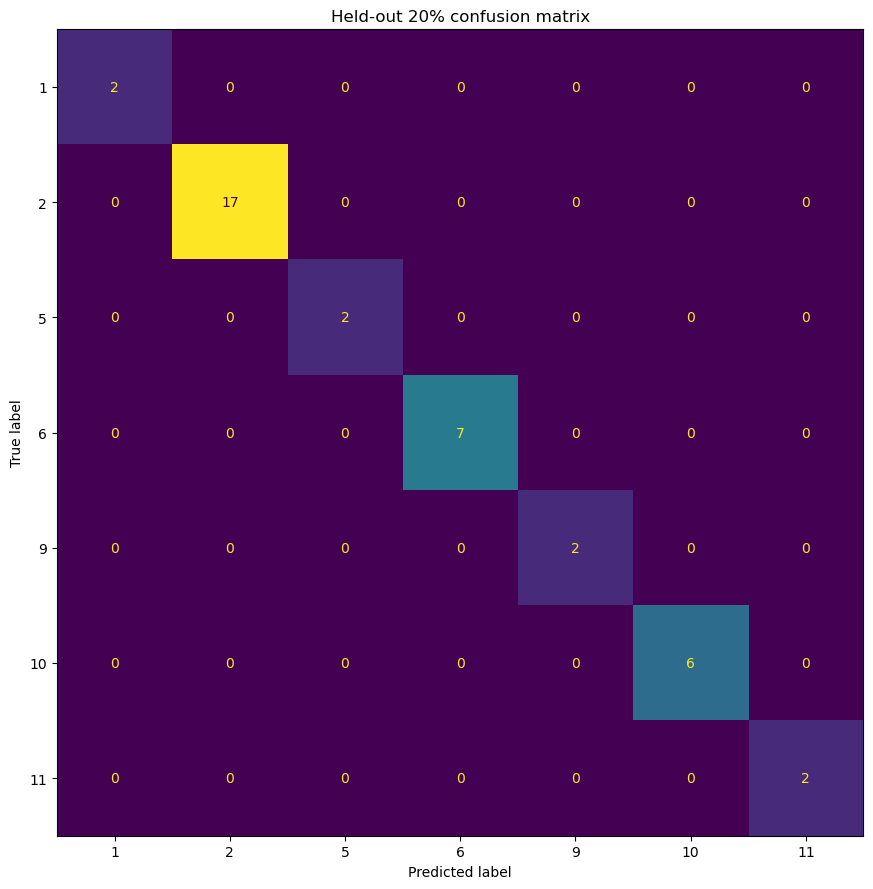

In [29]:
report = pd.DataFrame(
    classification_report(
        y_test, y_test_pred,
        output_dict=True,
        zero_division=0
    )
).T

display(report.round(3))

labels = sorted(y_test.unique())
cm = confusion_matrix(y_test, y_test_pred, labels=labels)

fig, ax = plt.subplots(figsize=(10, 9))
ConfusionMatrixDisplay(cm, display_labels=labels).plot(
    ax=ax, values_format="d", colorbar=False
)
ax.set_title("Held-out 20% confusion matrix")
plt.tight_layout()
plt.show()


In [30]:
# Which classes need more improvement / ground points?
needs = []
for cls in sorted(eval_table[CLASS_FIELD].unique()):
    key = str(int(cls))
    n = int((eval_table[CLASS_FIELD] == cls).sum())
    row = report.loc[key] if key in report.index else None
    precision = float(row["precision"]) if row is not None else np.nan
    recall = float(row["recall"]) if row is not None else np.nan
    f1 = float(row["f1-score"]) if row is not None else np.nan

    reasons = []
    if n < 30: reasons.append("more ground points")
    if f1 < 0.60: reasons.append("low F1")
    if recall < 0.60: reasons.append("low recall / missed class")
    if precision < 0.60: reasons.append("low precision / false positives")

    needs.append({
        "class": int(cls),
        "observations": n,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "priority": "HIGH" if reasons else "OK",
        "reason": "; ".join(reasons) if reasons else "adequate in this test"
    })

needs_df = pd.DataFrame(needs).sort_values(
    ["f1", "observations"], ascending=[True, True]
)
display(needs_df.round(3))


,class,observations,precision,recall,f1,priority,reason
6,11,8,1.0,1.0,1.0,HIGH,more ground points
4,9,9,1.0,1.0,1.0,HIGH,more ground points
2,5,10,1.0,1.0,1.0,HIGH,more ground points
0,1,11,1.0,1.0,1.0,HIGH,more ground points
5,10,32,1.0,1.0,1.0,OK,adequate in this test
3,6,34,1.0,1.0,1.0,OK,adequate in this test
1,2,83,1.0,1.0,1.0,OK,adequate in this test


In [31]:
# Confusion pairs: which true classes are most often being predicted as another class?
error_pairs = pd.DataFrame({
    "true_class": y_test.to_numpy(),
    "predicted_class": y_test_pred
})
error_pairs = error_pairs[error_pairs.true_class != error_pairs.predicted_class]

confused = (
    error_pairs.value_counts()
    .rename("misclassified_points")
    .reset_index()
    .sort_values("misclassified_points", ascending=False)
)

display(confused.head(20))


,true_class,predicted_class,misclassified_points


In [32]:
# Refit operational model on all usable postcard observations
model = RandomForestClassifier(
    n_estimators=400,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)
model.fit(
    training_array[MODEL_FEATURES],
    training_array[CLASS_FIELD].astype(int)
)


,n_estimators,400
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [33]:
model.predict(observations)

/srv/conda/envs/notebook/lib/python3.11/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


array([ 2,  1,  1,  2,  1,  2,  9, 10, 10, 10, 10,  9, 10, 10, 10, 10, 10,
       10,  6,  5, 10, 10, 10, 10, 10, 10,  5,  5,  5,  5,  6,  6,  6,  6,
        6,  6,  6,  6,  6,  6,  6,  6,  6,  6,  6,  6, 11, 11, 11, 11,  2,
        1,  1,  2,  1,  2,  9, 10, 10, 10, 10,  9, 10, 10, 10, 10, 10, 10,
        6,  5, 10, 10, 10, 10, 10, 10,  5,  5,  5,  5,  6,  6,  6,  6,  6,
        6,  6,  6,  6,  6,  6,  6,  6,  6,  6,  6, 11, 11, 11, 11,  1,  2,
        2,  1,  1,  1,  1,  1,  1,  3,  2,  2,  2,  2,  2,  2,  2,  2,  2,
        2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,
        9,  9,  9,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,
        2,  2,  2,  9,  9,  9,  9,  9,  2,  2,  2,  2,  2,  2,  2,  2,  2,
        2,  2,  2,  2,  2,  2,  1,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,
        2])

In [34]:
importance = pd.Series(
    model.feature_importances_,
    index=MODEL_FEATURES
).sort_values(ascending=False)

display(importance.rename("importance").to_frame())


,importance
swir22,0.095977
swir16,0.088353
blue,0.087839
red,0.085472
ndmi,0.081650
ndbi,0.080668
green,0.078572
rededge1,0.055325
ndvi_std,0.054517
ndvi,0.053753


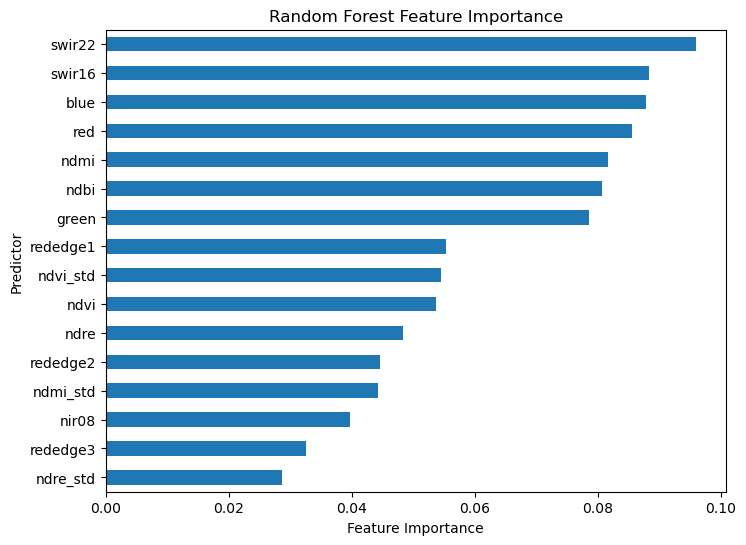

In [35]:
importance.sort_values().plot(
    kind="barh",
    figsize=(8, 6)
)

plt.xlabel("Feature Importance")
plt.ylabel("Predictor")
plt.title("Random Forest Feature Importance")

plt.show()

In [ ]:
joblib.dump(model, "cordia_v.2.0.model")

## Considerations

Do the results make sense?

What are some of the limitations of the visualisation?

### Next steps

The obvious next step is to fine tune the data. Perhaps download the points for this
region of interest as well as the RGB image and add and remove points until
there is a more representative training dataset.

### New AOI of your interest — run the trained model somewhere new

Participants can now choose **their own area of interest** and apply the trained model using exactly the same indicators used during training.

You can either:
1. provide a GeoJSON polygon, or
2. define a bounding box manually.

**Important:** transfer predictions should be interpreted carefully. A model trained in one landscape may not perform equally well in another island, forest type or environmental setting. Where possible, collect local validation points in the new AOI.


In [ ]:
# ==============================================================
# PARTICIPANT INPUT — CHOOSE YOUR OWN AOI
# ==============================================================

# OPTION A — GeoJSON polygon
NEW_AOI_FILE = "AOI/Santo_BigBay.geojson"

# OPTION B — manual bbox. Set USE_MANUAL_BBOX = True to use this.
USE_MANUAL_BBOX = False

new_min_lat = -15.65
new_min_lon = 166.95
new_max_lat = -15.45
new_max_lon = 167.20

if USE_MANUAL_BBOX:
    bbox_new = (
        new_min_lon, new_min_lat,
        new_max_lon, new_max_lat
    )
    aoiplot_gdf = gpd.GeoDataFrame(
        geometry=[gpd.GeoSeries.from_bbox(bbox_new).iloc[0]],
        crs="EPSG:4326"
    )
else:
    aoiplot_gdf = gpd.read_file(NEW_AOI_FILE).to_crs("EPSG:4326")
    bbox_new = tuple(aoiplot_gdf.total_bounds)

aoiplot_gdf.plot(edgecolor="red", facecolor="none")
plt.title("Participant New AOI")
plt.show()

print("New AOI bbox:", bbox_new)


In [ ]:
# Participant can also choose a new time period.
NEW_DATETIME = datetime

print("New AOI time period:", NEW_DATETIME)
print("Indicators that MUST remain consistent with training:")
print(MODEL_FEATURES)


In [ ]:
# Search Sentinel-2 for the participant AOI
items_new = client.search(
    collections=["sentinel-2-c1-l2a"],
    bbox=bbox_new,
    datetime=NEW_DATETIME,
    query={"eo:cloud_cover": {"lt": 30}},
).item_collection()

print(f"Found {len(items_new)} scenes")


In [ ]:
# Load the exact same bands used to create the trained model
data_new = load(
    items_new,
    measurements=[
        "red", "green", "blue",
        "rededge1", "rededge2", "rededge3",
        "nir08", "swir16", "swir22", "scl"
    ],
    bbox=bbox_new,
    chunks={"x": 1024, "y": 1024},
    groupby="solar_day",
)


In [ ]:
# Apply the SAME cloud mask and indicators as training
mask_flags = [0, 1, 3, 8, 9, 10, 11]
clear_new = ~data_new.scl.isin(mask_flags)

reflectance = [
    "red", "green", "blue",
    "rededge1", "rededge2", "rededge3",
    "nir08", "swir16", "swir22"
]

scaled_new = (
    data_new[reflectance]
    .where(clear_new)
    .where(data_new[reflectance] != 0)
    * 0.0001
).clip(0, 1)

eps = 1e-6
scaled_new["ndvi"] = (scaled_new.nir08-scaled_new.red)/(scaled_new.nir08+scaled_new.red+eps)
scaled_new["ndmi"] = (scaled_new.nir08-scaled_new.swir16)/(scaled_new.nir08+scaled_new.swir16+eps)
scaled_new["ndre"] = (scaled_new.nir08-scaled_new.rededge1)/(scaled_new.nir08+scaled_new.rededge1+eps)
scaled_new["ndbi"] = (scaled_new.swir16-scaled_new.nir08)/(scaled_new.swir16+scaled_new.nir08+eps)

clear_obs_new = scaled_new["red"].count("time")

median_nadala = scaled_new.median("time", skipna=True)
median_nadala["ndvi_std"] = scaled_new["ndvi"].std("time", skipna=True)
median_nadala["ndmi_std"] = scaled_new["ndmi"].std("time", skipna=True)
median_nadala["ndre_std"] = scaled_new["ndre"].std("time", skipna=True)

median_nadala = (
    median_nadala[MODEL_FEATURES]
    .where(clear_obs_new >= MIN_CLEAR_OBS)
    .compute()
)
clear_obs_new = clear_obs_new.compute()

print("New AOI feature cube ready.")


In [ ]:
# Visualise the new AOI cloud-robust composite
median_nadala.odc.explore(
    bands=("red", "green", "blue"),
    vmin=0,
    vmax=0.3
)


In [ ]:
# Predict the participant AOI + calculate confidence/uncertainty
cube_new = (
    median_nadala[MODEL_FEATURES]
    .to_array("feature")
    .transpose("y", "x", "feature")
    .values
)

valid_new = np.isfinite(cube_new).all(axis=2)

pred_new = np.full(valid_new.shape, -9999, dtype="int16")
conf_new = np.full(valid_new.shape, np.nan, dtype="float32")

if valid_new.any():
    X_new = cube_new[valid_new]
    pred_new[valid_new] = model.predict(X_new).astype("int16")
    conf_new[valid_new] = model.predict_proba(X_new).max(axis=1)

predicted_new_da = xr.DataArray(
    pred_new,
    coords={"y": median_nadala.y, "x": median_nadala.x},
    dims=["y", "x"],
    name="classification"
)

confidence_new_da = xr.DataArray(
    conf_new,
    coords={"y": median_nadala.y, "x": median_nadala.x},
    dims=["y", "x"],
    name="confidence"
)

uncertainty_new_da = 1.0 - confidence_new_da

print("New AOI prediction complete.")


In [ ]:
# Areas most useful for field checking:
# high model uncertainty but enough clear satellite observations.
UNCERTAINTY_THRESHOLD = 0.40

field_priority_new = (
    (uncertainty_new_da >= UNCERTAINTY_THRESHOLD) &
    (clear_obs_new >= MIN_CLEAR_OBS)
).astype("uint8")

print(
    "High-uncertainty pixels:",
    int(field_priority_new.sum().values)
)


In [ ]:
# Interactive new-AOI map
center = [
    aoiplot_gdf.geometry.centroid.y.mean(),
    aoiplot_gdf.geometry.centroid.x.mean()
]
m_new = folium.Map(location=center, zoom_start=10)

median_nadala.odc.to_rgba(
    bands=("red", "green", "blue"),
    vmin=0, vmax=0.3
).odc.add_to(m_new, name="Cloud-robust RGB")

predicted_new_da.astype("float32").odc.add_to(
    m_new, name="Predicted classes"
)

uncertainty_new_da.odc.add_to(
    m_new, name="Model uncertainty"
)

field_priority_new.odc.add_to(
    m_new, name="Priority field-check areas"
)

folium.GeoJson(
    aoiplot_gdf.__geo_interface__,
    name="New AOI"
).add_to(m_new)

folium.LayerControl().add_to(m_new)
m_new


In [ ]:
# Export participant AOI outputs for QGIS
from pathlib import Path
Path("Results").mkdir(exist_ok=True)

predicted_new_da.odc.write_cog(
    "Results/New_AOI_prediction.tif",
    overwrite=True,
    nodata=-9999
)

confidence_new_da.odc.write_cog(
    "Results/New_AOI_confidence.tif",
    overwrite=True
)

uncertainty_new_da.odc.write_cog(
    "Results/New_AOI_uncertainty.tif",
    overwrite=True
)

clear_obs_new.astype("int16").odc.write_cog(
    "Results/New_AOI_clear_observation_count.tif",
    overwrite=True
)

field_priority_new.odc.write_cog(
    "Results/New_AOI_field_priority.tif",
    overwrite=True
)

print("New AOI outputs exported to Results/")


In [ ]:
# New AOI summary
valid_pixels = int(valid_new.sum())
priority_pixels = int(field_priority_new.sum().values)

print("Valid classified pixels:", valid_pixels)
print("High-uncertainty / field-priority pixels:", priority_pixels)

if valid_pixels:
    print(
        "Field-priority share:",
        f"{100 * priority_pixels / valid_pixels:.2f}%"
    )

print("\nRemember: this is a TRANSFER prediction.")
print("Local ground-validation points should be collected before treating it as an accuracy-assessed map.")
